# Газ и нефть на MOEX: свечи, волатильность, MACD

Фьючерсы **NG** (природный газ, USD/MMBtu) и **BR** (Brent, USD/bbl) по данным MOEX AlgoPack,
обработанные через `exchange`.

### Какой ряд на каком графике и почему

Вендор отдаёт ряд, склеенный по ближайшей экспирации и **не скорректированный**: на каждом
переходе между контрактами в цене остаётся ступень. По NG медианная ступень **+384 б.п.**, 95%
переходов выше 100 б.п., и за 2020–2026 склейка создаёт **+140 процентных пунктов** доходности,
которой не существует. Поэтому ряд выбирается под вопрос, а не один на всё:

| § | Вопрос | Ряд |
|---|---|---|
| 1–3 | Сколько стоил инструмент? | **Котировки как есть** — реальные уровни ближнего контракта |
| 4 | Насколько он был волатилен? | **Торгуемые доходности** — бары роллов исключены |
| 5–6 | Что показывает MACD? | **Ratio-скорректированный ряд** — EMA не должны реагировать на смену контракта |
| 7–8 | Что заработала бы позиция? | **Торгуемые доходности** |

Пятая строка — не формальность. MACD на нескорректированном ряде читает календарь контрактов:
обе его EMA отреагируют на 80 ступеней по +3.8%, и пересечения будут происходить там, где сменился
инструмент.

In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.collections import LineCollection, PatchCollection
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter

from exchange.core.timeframe import empirical_bars_per_year
from exchange.data.moex import moex_continuous
from exchange.data.prespliced import splice_artefact
from exchange.strategies.base import macd

CANDIDATES = [
    Path.cwd().parents[1] / "data" / "raw" / "moex_algopack",
    Path.cwd().parent / "data" / "raw" / "moex_algopack",
    Path("/home/user/moex"),
]
DATA = next((p for p in CANDIDATES if p.is_dir()), None)
if DATA is None:
    raise FileNotFoundError(f"не найден каталог AlgoPack; искал: {[str(p) for p in CANDIDATES]}")
print("данные:", DATA)

данные: /home/user/moex


In [2]:
# --- Палитра --------------------------------------------------------------
# Категориальные слоты 1-2 для идентичности инструмента; дивергентная пара
# синий<->красный для полярности (рост/падение свечи, знак гистограммы MACD).
# Проверено validate_palette.js: CVD dE 24.7, normal-vision dE 33.6, контраст >= 3:1.
#
# Зелёный и красный — отраслевой стандарт свечей и худший возможный выбор:
# это ровно та пара, которую не различает 8% мужчин. Синий/красный несёт ту же
# полярность (холодный против тёплого) и остаётся различимым при дейтеранопии.
SERIES_1, SERIES_2 = "#2a78d6", "#eb6834"     # NG, BR
UP, DOWN           = "#2a78d6", "#e34948"     # рост, падение
SURFACE, INK, INK_2 = "#fcfcfb", "#0b0b0b", "#52514e"
MUTED, GRID, AXIS   = "#898781", "#e1e0d9", "#c3c2b7"

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.linewidth": 0.8, "axes.edgecolor": AXIS,
    "lines.linewidth": 2.0, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "figure.dpi": 130,
})


def frame(ax, title="", subtitle="", ylabel="", grid_axis="y"):
    ax.grid(True, axis=grid_axis, color=GRID, linewidth=0.8, linestyle="-", zorder=0)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
    if title:
        ax.set_title(title, color=INK, fontsize=12.5, fontweight="semibold", loc="left", pad=16)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, color=INK_2, fontsize=9.5, va="bottom")
    if ylabel:
        ax.set_ylabel(ylabel, color=INK_2, fontsize=9.5)
    ax.tick_params(length=3, color=AXIS)


def end_label(ax, series, color, text=None, x=None):
    xi = len(series) - 1 if x is None else x
    y = float(series.iloc[-1])
    ax.plot([xi], [y], marker="o", markersize=5, color=color, zorder=5,
            markeredgecolor=SURFACE, markeredgewidth=1.5)
    ax.annotate(text or f"{y:,.2f}", xy=(xi, y), xytext=(8, 0), textcoords="offset points",
                va="center", color=INK_2, fontsize=9.5, fontweight="semibold")


def date_ticks(ax, index, n=8):
    """Подписи дат на порядковой оси: свечи равной ширины, без дыр на выходных."""
    positions = np.linspace(0, len(index) - 1, n).round().astype(int)
    ax.set_xticks(positions)
    ax.set_xticklabels([index[p].strftime("%d.%m.%y") for p in positions])

In [3]:
def draw_candles(ax, bars, width=0.62):
    """Свечи на порядковой оси.

    Тело — прямоугольник open->close, фитиль — линия low..high в 1px того же
    цвета. Ширина тела 0.62 слота: остаток — воздух между свечами, а не рамка
    вокруг них. Доджи (open == close) рисуется как горизонтальная черта,
    иначе он исчез бы.
    """
    x = np.arange(len(bars))
    o = bars["open"].to_numpy(float)
    h = bars["high"].to_numpy(float)
    low = bars["low"].to_numpy(float)
    c = bars["close"].to_numpy(float)
    rising = c >= o

    for mask, color in ((rising, UP), (~rising, DOWN)):
        if not mask.any():
            continue
        ax.add_collection(LineCollection(
            [[(xi, lo), (xi, hi)] for xi, lo, hi in zip(x[mask], low[mask], h[mask])],
            colors=color, linewidths=1.0, zorder=2,
        ))
        bodies, flats = [], []
        for xi, oi, ci in zip(x[mask], o[mask], c[mask]):
            height = abs(ci - oi)
            if height < 1e-12:
                flats.append([(xi - width / 2, oi), (xi + width / 2, oi)])
            else:
                bodies.append(Rectangle((xi - width / 2, min(oi, ci)), width, height))
        if bodies:
            ax.add_collection(PatchCollection(bodies, facecolor=color, edgecolor="none", zorder=3))
        if flats:
            ax.add_collection(LineCollection(flats, colors=color, linewidths=1.4, zorder=3))

    ax.set_xlim(-1, len(bars))
    pad = (np.nanmax(h) - np.nanmin(low)) * 0.06
    ax.set_ylim(np.nanmin(low) - pad, np.nanmax(h) + pad)
    return x


def mark_rolls(ax, bars, label=True):
    """Тонкие вертикали там, где сменился контракт."""
    positions = np.flatnonzero(bars["is_roll"].to_numpy(bool))
    for p in positions:
        ax.axvline(p, color=MUTED, linewidth=0.8, alpha=0.45, zorder=1)
    if label and len(positions):
        ax.annotate("смена контракта", xy=(positions[0], ax.get_ylim()[1]),
                    xytext=(3, -12), textcoords="offset points",
                    color=MUTED, fontsize=8.5, va="top")
    return positions

In [4]:
# --- Загрузка --------------------------------------------------------------
def daily(series):
    bars = series.bars.resample("1D").agg(
        {"open": "first", "high": "max", "low": "min",
         "close": "last", "volume": "sum", "is_roll": "max"}
    ).dropna(subset=["close"])
    bars["is_roll"] = bars["is_roll"].astype(bool)
    return bars


panels = {}
for ticker in ("ng", "br"):
    raw = moex_continuous(DATA, ticker, "60m", adjustment="none")
    adjusted = moex_continuous(DATA, ticker, "60m", adjustment="ratio")
    daily_raw = daily(raw)
    # Торгуемые дневные доходности: часовые с исключёнными роллами, сжатые в день.
    tradeable_daily = (1.0 + raw.tradeable_returns().fillna(0.0)).resample("1D").prod() - 1.0
    panels[raw.root] = {
        "quoted": daily_raw,
        "adjusted": daily(adjusted),
        "returns": tradeable_daily.reindex(daily_raw.index).fillna(0.0),
        "artefact": splice_artefact(raw),
        "series": raw,
        "color": SERIES_1 if raw.root == "NG" else SERIES_2,
        "unit": "USD / MMBtu" if raw.root == "NG" else "USD / баррель",
    }

pd.DataFrame({
    root: {
        "дневных бар": len(p["quoted"]),
        "с": p["quoted"].index[0].strftime("%Y-%m-%d"),
        "по": p["quoted"].index[-1].strftime("%Y-%m-%d"),
        "роллов": p["artefact"]["n_rolls"],
        "медианная ступень, б.п.": round(p["artefact"]["median_gap_bps"], 1),
        "артефакт склейки": f"{p['artefact']['splice_artefact']:+.1%}",
        "последняя цена": round(float(p["quoted"]["close"].iloc[-1]), 3),
    }
    for root, p in panels.items()
})

13:38:11 INFO    exchange.data.moex | ng/60m: 25854 bars, 2020-02-03 07:00:00+00:00..2026-10-03 15:00:00+00:00, 81 contract(s)


13:38:11 INFO    exchange.data.prespliced | NG: 25854 bars, 81 contract(s), 80 roll(s), adjustment=none


13:38:11 INFO    exchange.data.moex | ng/60m: 25854 bars, 2020-02-03 07:00:00+00:00..2026-10-03 15:00:00+00:00, 81 contract(s)


13:38:11 INFO    exchange.data.prespliced | NG: 25854 bars, 81 contract(s), 80 roll(s), adjustment=ratio


13:38:11 INFO    exchange.data.moex | br/60m: 53630 bars, 2011-12-19 06:00:00+00:00..2026-10-03 15:00:00+00:00, 177 contract(s)


13:38:11 INFO    exchange.data.prespliced | BR: 53630 bars, 177 contract(s), 176 roll(s), adjustment=none


13:38:11 INFO    exchange.data.moex | br/60m: 53630 bars, 2011-12-19 06:00:00+00:00..2026-10-03 15:00:00+00:00, 177 contract(s)


13:38:11 INFO    exchange.data.prespliced | BR: 53630 bars, 177 contract(s), 176 roll(s), adjustment=ratio


,NG,BR
дневных бар,1782,3828
с,2020-02-03,2011-12-19
по,2026-10-03,2026-10-03
роллов,80,176
"медианная ступень, б.п.",384.0,-31.0
артефакт склейки,+139.7%,+16.1%
последняя цена,3.043,102.44


## 1. Свечи: природный газ

Последние 120 торговых дней. Больше на один экран не поместится: при 1 780 днях свеча была бы
уже пикселя, и график превратился бы в неряшливую линию — свечи имеют смысл на горизонте, где
видно отдельный день.

Ось порядковая, а не календарная: иначе выходные оставляли бы дыры, а свечи стали бы разной
ширины. Вертикальные линии — смены контракта; разрыв цены на них не является движением рынка.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


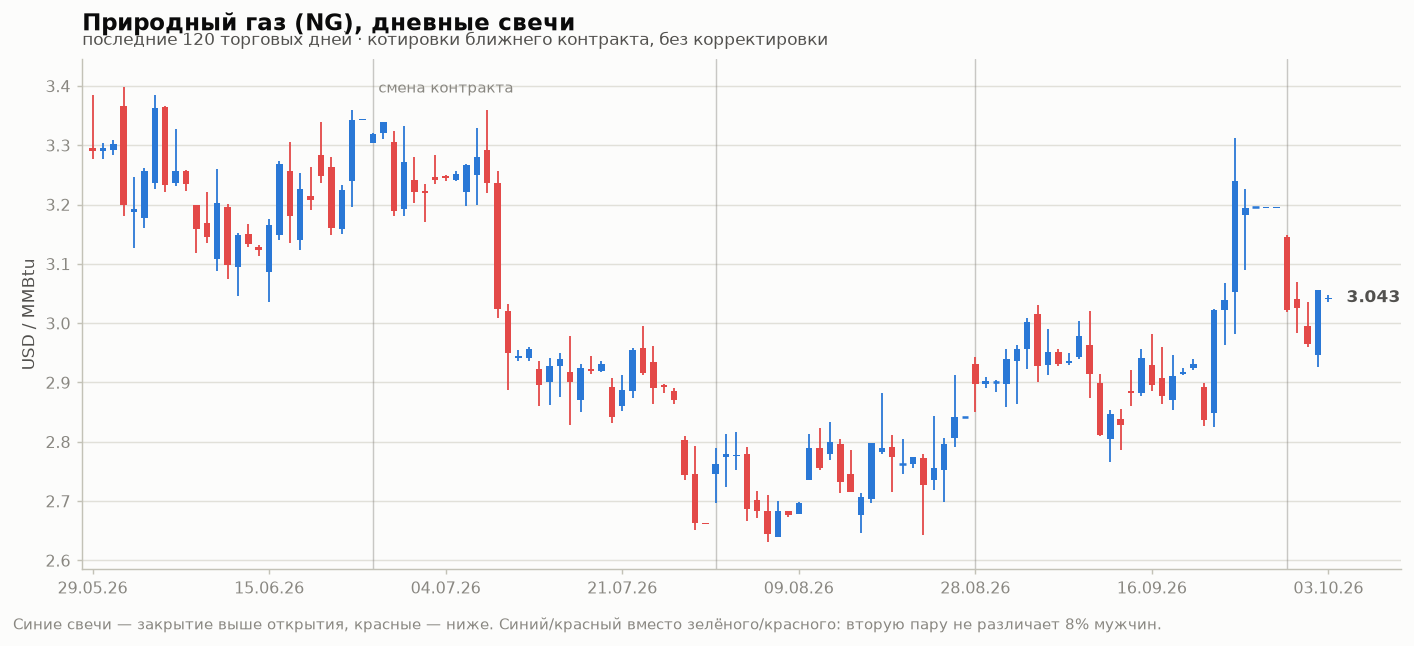

In [5]:
WINDOW = 120
ng = panels["NG"]["quoted"].iloc[-WINDOW:]

fig, ax = plt.subplots(figsize=(11, 4.8))
draw_candles(ax, ng)
frame(ax, "Природный газ (NG), дневные свечи",
      f"последние {WINDOW} торговых дней · котировки ближнего контракта, без корректировки",
      ylabel=panels["NG"]["unit"])
mark_rolls(ax, ng)
date_ticks(ax, ng.index)
last = float(ng["close"].iloc[-1])
ax.annotate(f"{last:,.3f}", xy=(len(ng) - 1, last), xytext=(10, 0), textcoords="offset points",
            va="center", color=INK_2, fontsize=9.5, fontweight="semibold")
ax.set_xlim(-1, len(ng) + 6)
fig.text(0.008, -0.02, "Синие свечи — закрытие выше открытия, красные — ниже. "
         "Синий/красный вместо зелёного/красного: вторую пару не различает 8% мужчин.",
         color=MUTED, fontsize=8.5)
plt.tight_layout()
plt.show()

## 2. Свечи: нефть Brent

То же окно и та же конструкция. Brent в основном в бэквордации, поэтому её ступени на роллах
мельче и разнонаправленны: медианная −31 б.п. против +384 б.п. у газа.

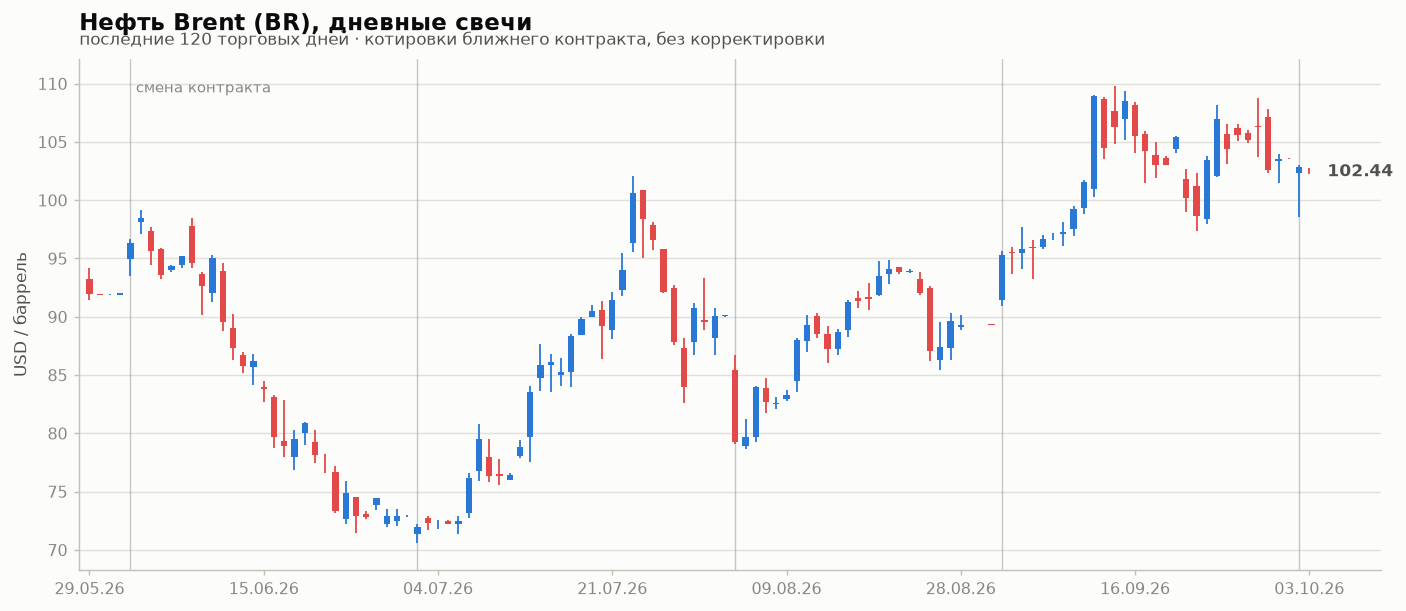

In [6]:
br = panels["BR"]["quoted"].iloc[-WINDOW:]

fig, ax = plt.subplots(figsize=(11, 4.8))
draw_candles(ax, br)
frame(ax, "Нефть Brent (BR), дневные свечи",
      f"последние {WINDOW} торговых дней · котировки ближнего контракта, без корректировки",
      ylabel=panels["BR"]["unit"])
mark_rolls(ax, br)
date_ticks(ax, br.index)
last = float(br["close"].iloc[-1])
ax.annotate(f"{last:,.2f}", xy=(len(br) - 1, last), xytext=(10, 0), textcoords="offset points",
            va="center", color=INK_2, fontsize=9.5, fontweight="semibold")
ax.set_xlim(-1, len(br) + 6)
plt.tight_layout()
plt.show()

## 3. Полная история цен

Свечи отвечают на вопрос «что происходило в последние месяцы». На вопрос «где мы в масштабе
истории» отвечает линия — две панели, по инструменту на панель, у каждой своя шкала. Две шкалы
на **одном** графике были бы ошибкой: наклоны стали бы несопоставимы. Две панели — нет: это два
графика, стоящие рядом.

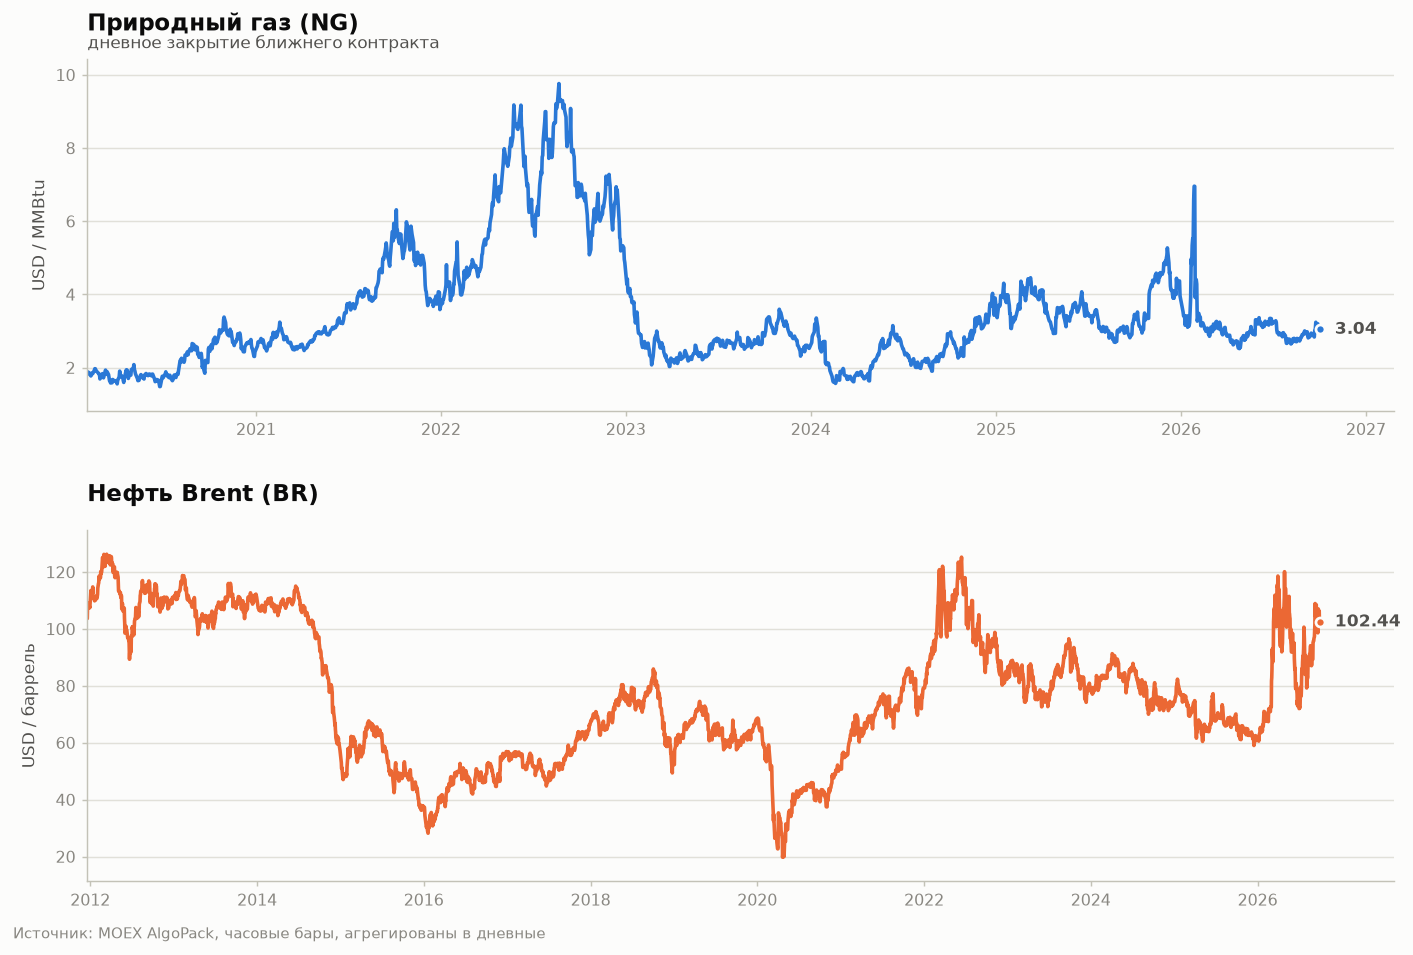

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7.2), sharex=False)
for ax, root in zip(axes, ("NG", "BR")):
    p = panels[root]
    close = p["quoted"]["close"]
    ax.plot(close.index, close.to_numpy(), color=p["color"])
    frame(ax, f"{'Природный газ (NG)' if root == 'NG' else 'Нефть Brent (BR)'}",
          "дневное закрытие ближнего контракта" if root == "NG" else "",
          ylabel=p["unit"])
    end_label(ax, close, p["color"], x=close.index[-1])
    span = close.index[-1] - close.index[0]
    ax.set_xlim(close.index[0], close.index[-1] + span * 0.06)
    ax.margins(y=0.08)
fig.text(0.008, -0.01, "Источник: MOEX AlgoPack, часовые бары, агрегированы в дневные",
         color=MUTED, fontsize=8.5)
plt.tight_layout(h_pad=2.5)
plt.show()

## 4. Волатильность

Реализованная волатильность: стандартное отклонение дневных доходностей в скользящем окне 20
торговых дней, приведённое к годовой. Единицы общие (проценты годовых), поэтому оба инструмента
корректно ложатся на одну ось.

Два решения, которые здесь важнее формулы:

* **Доходности торгуемые** — бары роллов исключены. Иначе ступень +384 б.п. попадала бы в окно и
  давала всплеск волатильности каждый месяц, ровно в день смены контракта.
* **Приведение к годовой — по эмпирическому числу баров в году**, посчитанному по самому индексу,
  а не по номинальным 252. Для этих рядов получается ~260: ошибка в этом множителе переносится в
  каждое число на графике.

Именно этот график — единственное, что сканер нашёл на данных как устойчиво измеримое:
кластеризация волатильности со значимостью до p = 1.7e-200. Направление непредсказуемо, размах — нет.

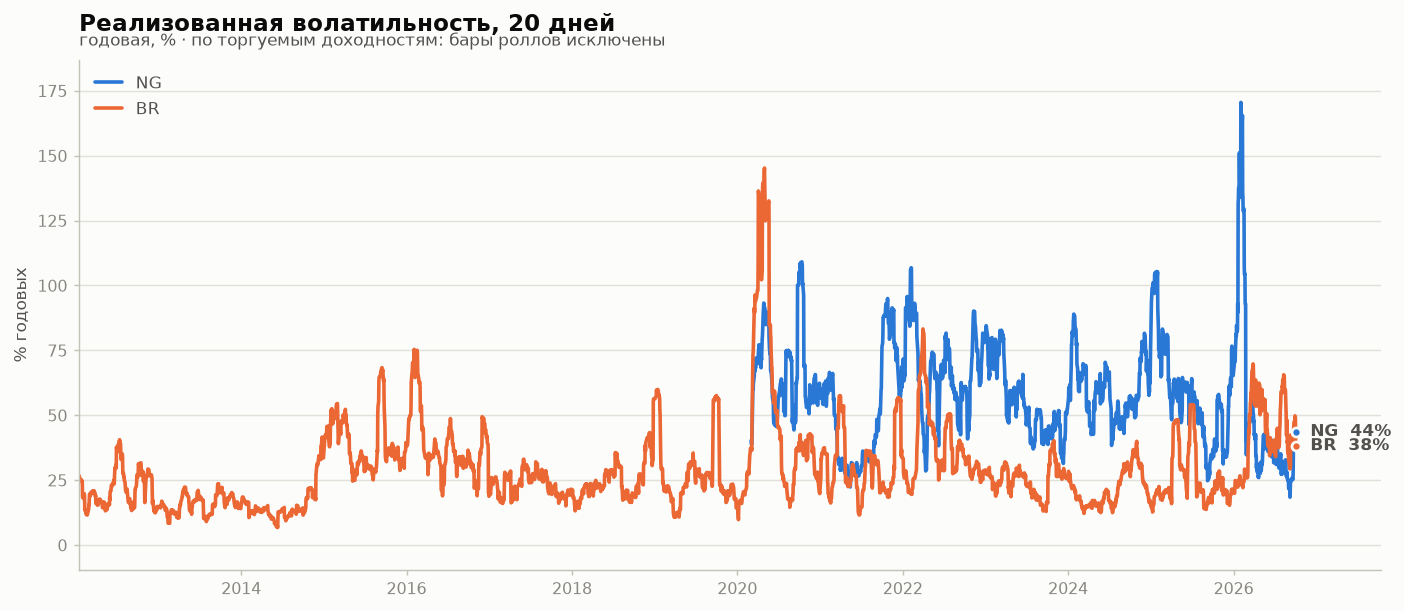

,NG,BR
медиана,56%,26%
минимум,18%,7%
максимум,171%,145%
последняя,44%,38%
95-й перцентиль,92%,58%


In [8]:
fig, ax = plt.subplots(figsize=(11, 4.8))
vol_table = {}
for root in ("NG", "BR"):
    p = panels[root]
    ppy = empirical_bars_per_year(p["quoted"].index)
    vol = p["returns"].rolling(20, min_periods=20).std(ddof=1) * np.sqrt(ppy) * 100.0
    vol_table[root] = vol
    ax.plot(vol.index, vol.to_numpy(), color=p["color"], label=root)

frame(ax, "Реализованная волатильность, 20 дней",
      "годовая, % · по торгуемым доходностям: бары роллов исключены",
      ylabel="% годовых")
for root in ("NG", "BR"):
    series = vol_table[root].dropna()
    end_label(ax, series, panels[root]["color"],
              text=f"{root}  {float(series.iloc[-1]):,.0f}%", x=series.index[-1])
ax.legend(frameon=False, loc="upper left", fontsize=9.5, handlelength=1.6, labelcolor=INK_2)
start = min(v.dropna().index[0] for v in vol_table.values())
end = max(v.dropna().index[-1] for v in vol_table.values())
ax.set_xlim(start, end + (end - start) * 0.07)
ax.margins(y=0.10)
plt.tight_layout()
plt.show()

pd.DataFrame({
    root: {
        "медиана": f"{v.median():.0f}%",
        "минимум": f"{v.min():.0f}%",
        "максимум": f"{v.max():.0f}%",
        "последняя": f"{v.dropna().iloc[-1]:.0f}%",
        "95-й перцентиль": f"{v.quantile(0.95):.0f}%",
    }
    for root, v in vol_table.items()
})

## 5. MACD: природный газ

Классические параметры 12 / 26 / 9. Верхняя панель — цена, нижняя — MACD: линия (разность быстрой
и медленной EMA), её сигнальная EMA и гистограмма их разности.

**Ряд здесь ratio-скорректированный.** На нескорректированном обе EMA отреагировали бы на ступени
роллов, и пересечения линий происходили бы в дни смены контракта — индикатор читал бы календарь, а
не рынок.

Индикатор взят из пакета (`exchange.strategies.base.macd`), а не написан в ноутбуке: там он
покрыт тестом на причинность, который доказывает, что значение на баре *t* не зависит ни от одного
последующего бара.

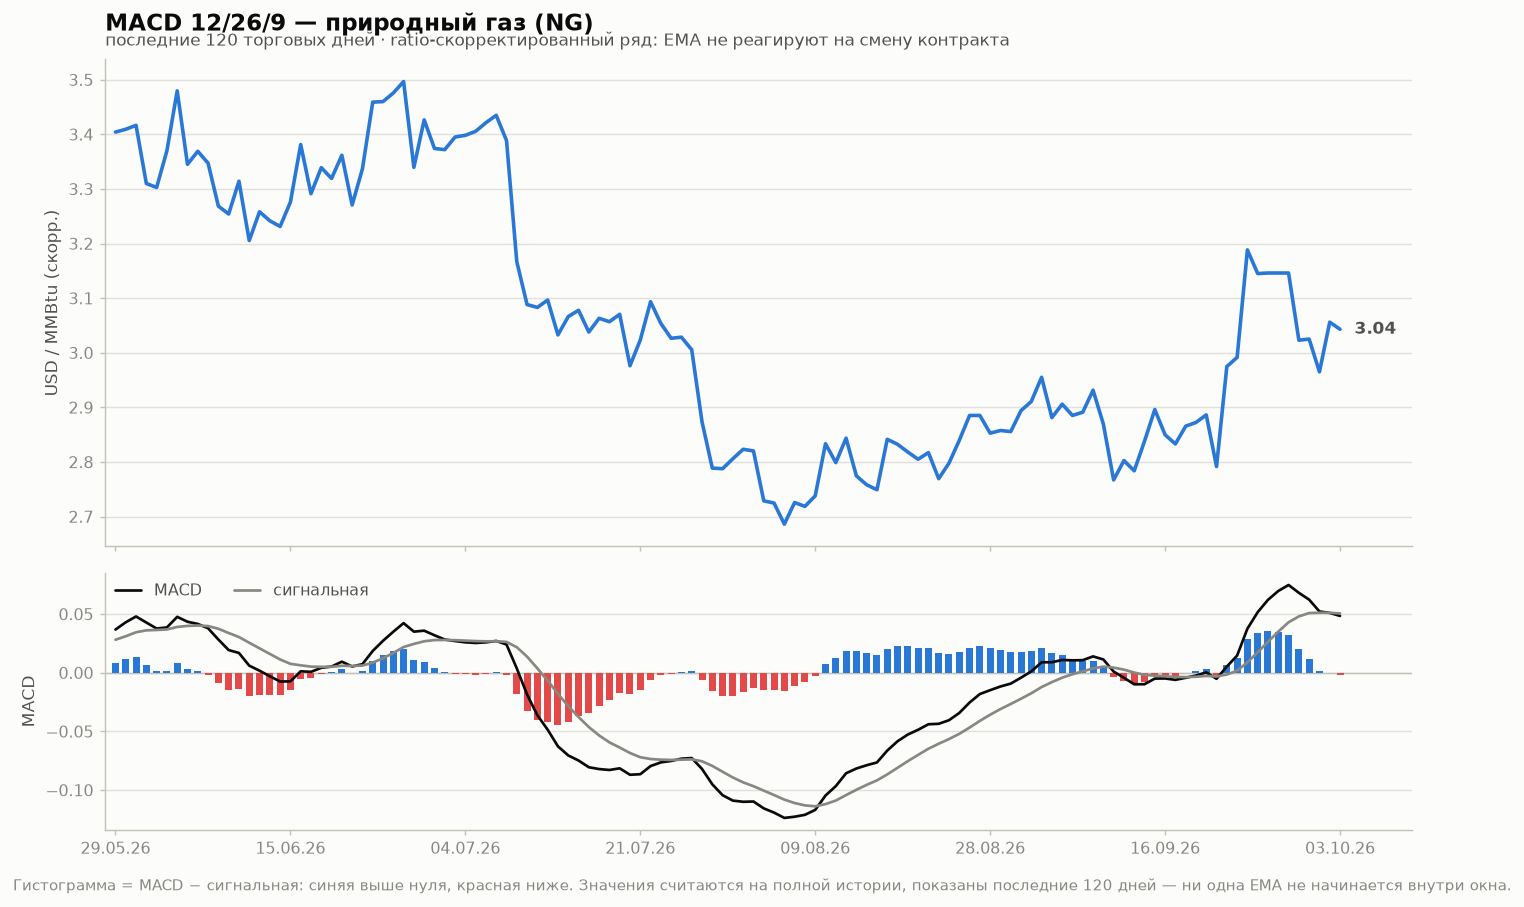

In [9]:
def macd_figure(root, window=WINDOW, fast=12, slow=26, signal=9):
    p = panels[root]
    close = p["adjusted"]["close"]
    lines = macd(close, fast=fast, slow=slow, signal=signal)
    close, lines = close.iloc[-window:], lines.iloc[-window:]
    x = np.arange(len(close))

    fig, (ax_price, ax_macd) = plt.subplots(
        2, 1, figsize=(11, 6.8), sharex=True, gridspec_kw={"height_ratios": [1.9, 1.0]}
    )
    ax_price.plot(x, close.to_numpy(), color=p["color"])
    frame(ax_price, f"MACD {fast}/{slow}/{signal} — {'природный газ (NG)' if root == 'NG' else 'нефть Brent (BR)'}",
          f"последние {window} торговых дней · ratio-скорректированный ряд: "
          "EMA не реагируют на смену контракта",
          ylabel=f"{p['unit']} (скорр.)")
    ax_price.annotate(f"{float(close.iloc[-1]):,.2f}", xy=(x[-1], float(close.iloc[-1])),
                      xytext=(8, 0), textcoords="offset points", va="center",
                      color=INK_2, fontsize=9.5, fontweight="semibold")

    hist = lines["histogram"].to_numpy()
    colors = np.where(hist >= 0, UP, DOWN)
    ax_macd.bar(x, hist, width=0.68, color=colors, linewidth=0, zorder=2)
    ax_macd.plot(x, lines["macd"].to_numpy(), color=INK, linewidth=1.5, zorder=3, label="MACD")
    ax_macd.plot(x, lines["signal"].to_numpy(), color=MUTED, linewidth=1.5, zorder=3, label="сигнальная")
    ax_macd.axhline(0.0, color=AXIS, linewidth=0.8, zorder=1)
    frame(ax_macd, ylabel="MACD")
    ax_macd.legend(frameon=False, loc="upper left", fontsize=9, ncols=2,
                   handlelength=1.6, labelcolor=INK_2, borderaxespad=0.2)
    fig.text(0.008, -0.015, "Гистограмма = MACD − сигнальная: синяя выше нуля, красная ниже. "
             "Значения считаются на полной истории, показаны последние "
             f"{window} дней — ни одна EMA не начинается внутри окна.",
             color=MUTED, fontsize=8.5)
    date_ticks(ax_macd, close.index)
    for ax in (ax_price, ax_macd):
        ax.set_xlim(-1, len(close) + 6)
    plt.tight_layout(h_pad=1.2)
    plt.show()
    return lines


ng_macd = macd_figure("NG")

## 6. MACD: нефть Brent

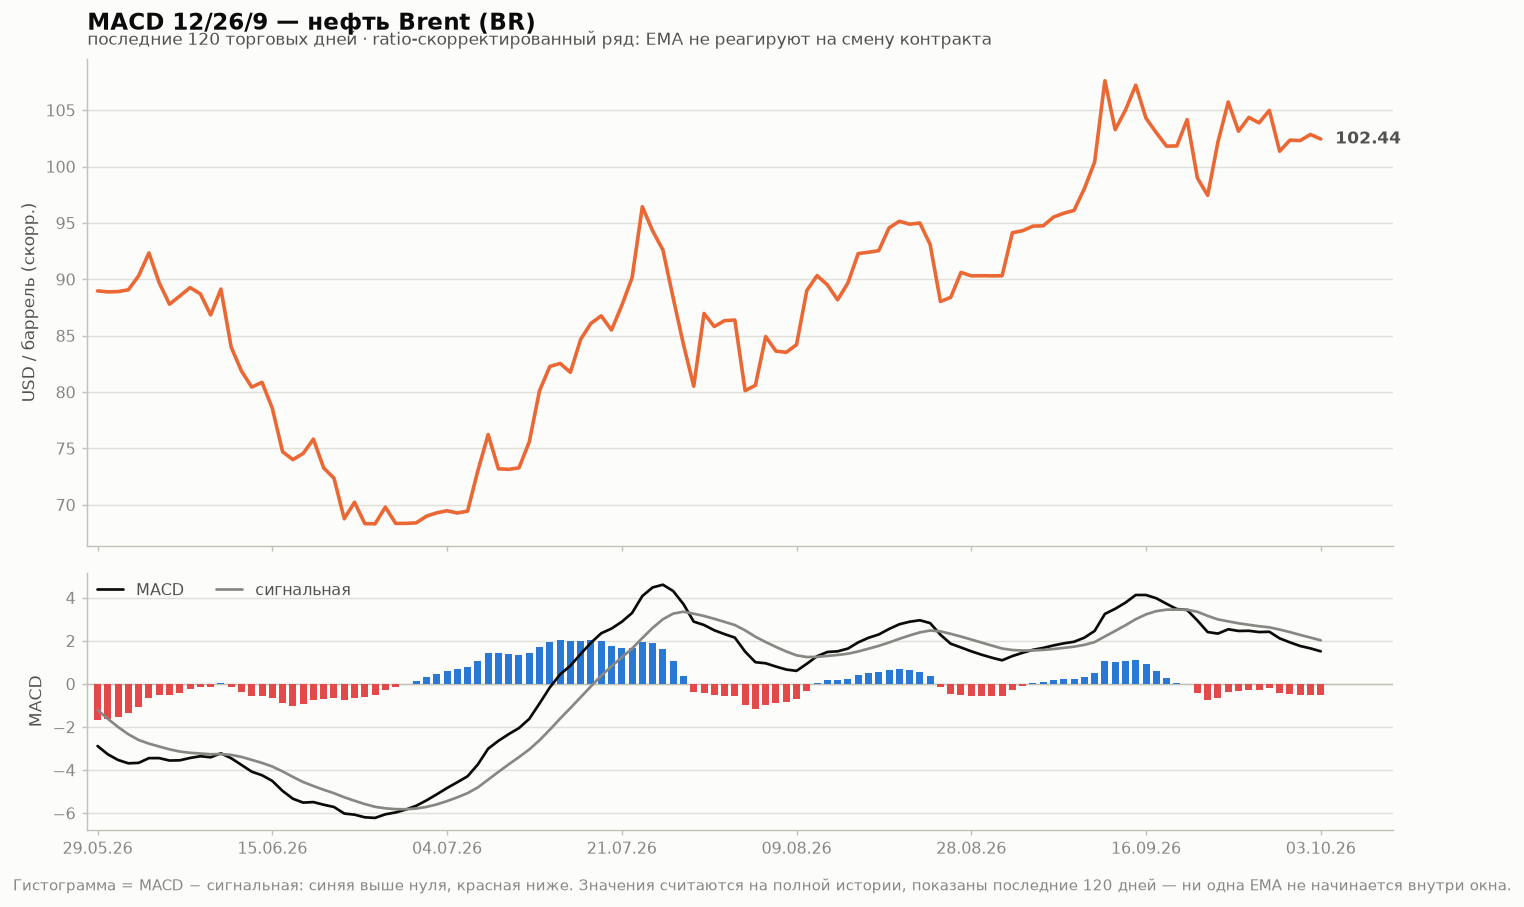

In [10]:
br_macd = macd_figure("BR")

## 7. Что заработала бы позиция

Цены в разных единицах, поэтому сравнение идёт через индекс: оба ряда = 100 на общем старте, по
торгуемым доходностям. Одна ось, и она означает одно и то же.

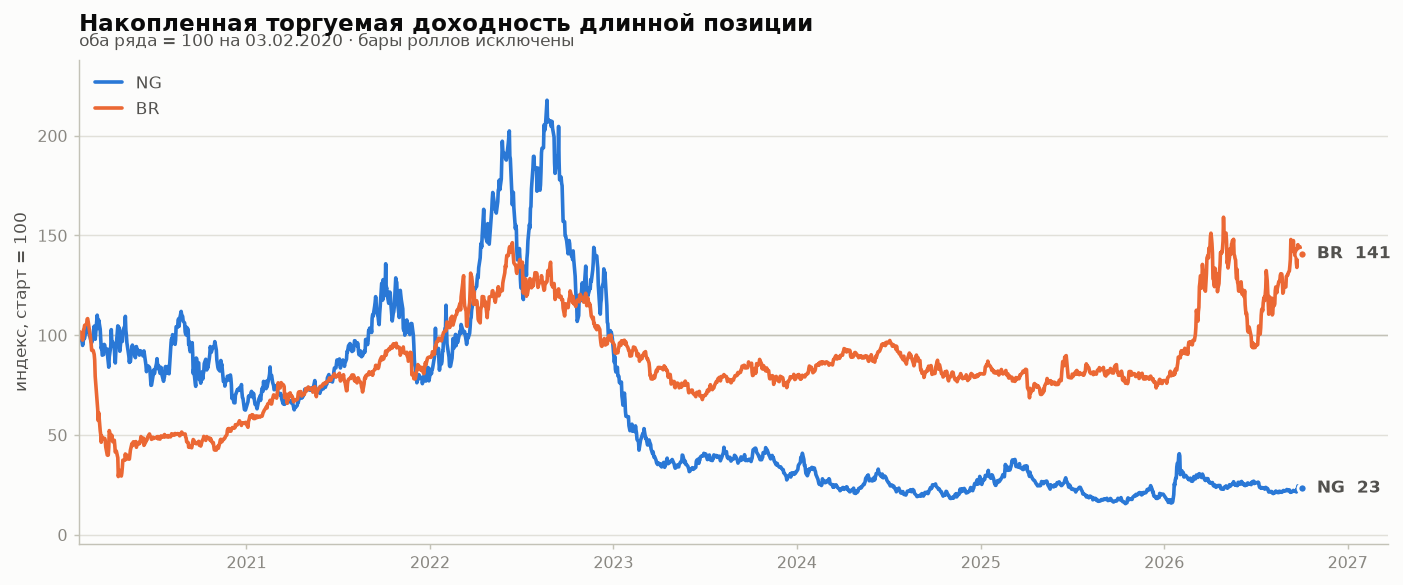

In [11]:
start = max(panels["NG"]["returns"].index[0], panels["BR"]["returns"].index[0])
fig, ax = plt.subplots(figsize=(11, 4.6))
curves = {}
for root in ("NG", "BR"):
    r = panels[root]["returns"].loc[start:]
    curves[root] = (1.0 + r).cumprod() * 100.0
    ax.plot(curves[root].index, curves[root].to_numpy(), color=panels[root]["color"], label=root)
ax.axhline(100.0, color=AXIS, linewidth=0.8, zorder=1)
frame(ax, "Накопленная торгуемая доходность длинной позиции",
      f"оба ряда = 100 на {start:%d.%m.%Y} · бары роллов исключены", ylabel="индекс, старт = 100")
for root in ("NG", "BR"):
    end_label(ax, curves[root], panels[root]["color"],
              text=f"{root}  {float(curves[root].iloc[-1]):,.0f}", x=curves[root].index[-1])
ax.legend(frameon=False, loc="upper left", fontsize=9.5, handlelength=1.6, labelcolor=INK_2)
span = curves["NG"].index[-1] - start
ax.set_xlim(start, curves["NG"].index[-1] + span * 0.07)
ax.margins(y=0.10)
plt.tight_layout()
plt.show()

## 8. Чего стоит сырой ряд вендора

Сравниваются не уровни цен, а накопленная доходность: вопрос в том, сколько движения создаёт сама
склейка. Расхождение линий — это не два взгляда на рынок, а ровно та доходность, которую
изготавливают 80 переходов контанго.

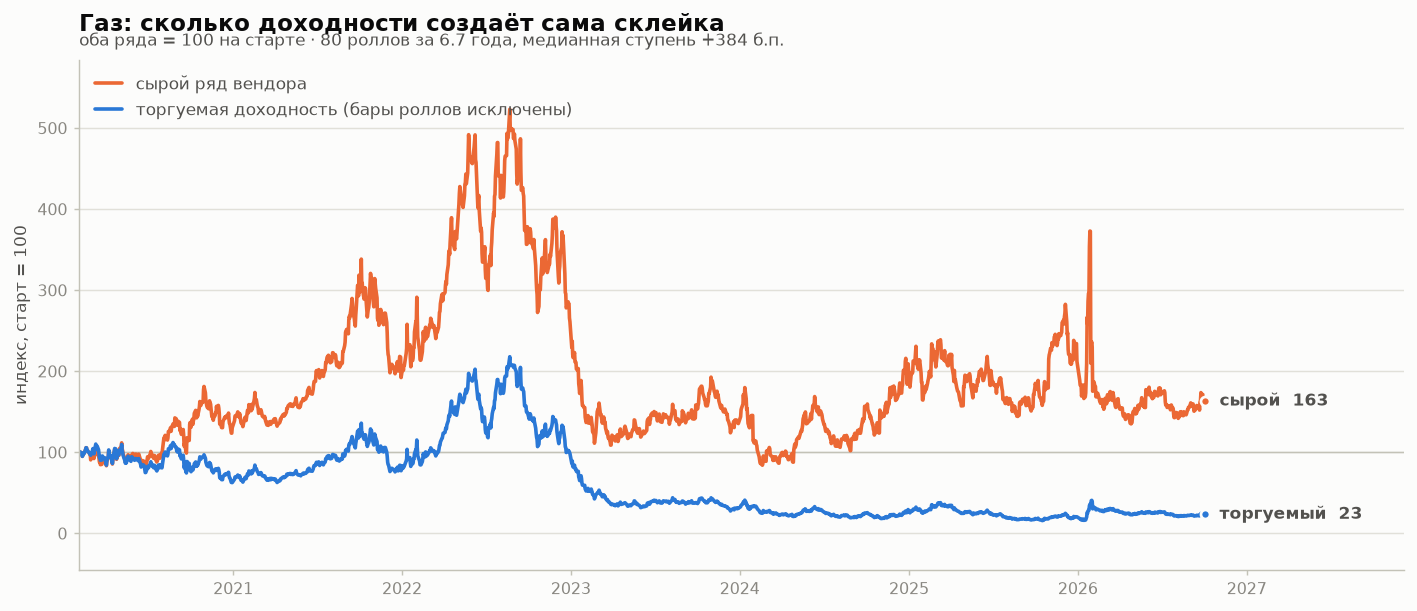

сырой ряд за период:  +63.1%
торгуемая доходность: -76.6%
создано склейкой:     +139.7%


In [12]:
art = panels["NG"]["artefact"]
hourly = panels["NG"]["series"].bars["close"]
raw_curve = (hourly / float(hourly.iloc[0]) * 100.0).resample("1D").last().dropna()
tradeable = panels["NG"]["series"].tradeable_returns().fillna(0.0)
tradeable_curve = ((1.0 + tradeable).cumprod() * 100.0).resample("1D").last().dropna()

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(raw_curve.index, raw_curve.to_numpy(), color=SERIES_2, label="сырой ряд вендора")
ax.plot(tradeable_curve.index, tradeable_curve.to_numpy(), color=SERIES_1,
        label="торгуемая доходность (бары роллов исключены)")
ax.axhline(100.0, color=AXIS, linewidth=0.8, zorder=1)
years = (raw_curve.index[-1] - raw_curve.index[0]).days / 365.25
frame(ax, "Газ: сколько доходности создаёт сама склейка",
      f"оба ряда = 100 на старте · {art['n_rolls']} роллов за {years:.1f} года, "
      f"медианная ступень {art['median_gap_bps']:+.0f} б.п.", ylabel="индекс, старт = 100")
end_label(ax, raw_curve, SERIES_2, text=f"сырой  {float(raw_curve.iloc[-1]):,.0f}", x=raw_curve.index[-1])
end_label(ax, tradeable_curve, SERIES_1, text=f"торгуемый  {float(tradeable_curve.iloc[-1]):,.0f}",
          x=tradeable_curve.index[-1])
ax.legend(frameon=False, loc="upper left", fontsize=9.5, handlelength=1.6, labelcolor=INK_2)
ax.set_xlim(raw_curve.index[0], raw_curve.index[-1] + pd.Timedelta(days=430))
ax.margins(y=0.12)
plt.tight_layout()
plt.show()

print(f"сырой ряд за период:  {art['raw_total_return']:+.1%}")
print(f"торгуемая доходность: {art['tradeable_total_return']:+.1%}")
print(f"создано склейкой:     {art['splice_artefact']:+.1%}")

## 9. Числа

График показывает форму, таблица — значения; идентичность ряда не передаётся одним только цветом.

In [13]:
pd.DataFrame({
    "NG закрытие, USD/MMBtu": panels["NG"]["quoted"]["close"].resample("YE").last().round(3),
    "NG волатильность, %": vol_table["NG"].resample("YE").mean().round(0),
    "BR закрытие, USD/bbl": panels["BR"]["quoted"]["close"].resample("YE").last().round(2),
    "BR волатильность, %": vol_table["BR"].resample("YE").mean().round(0),
}).rename(lambda t: t.year).rename_axis("год")

,"NG закрытие, USD/MMBtu","NG волатильность, %","BR закрытие, USD/bbl","BR волатильность, %"
год,,,,
2011,NaN,NaN,107.41,NaN
2012,NaN,NaN,110.69,22.0
2013,NaN,NaN,111.10,16.0
2014,NaN,NaN,57.39,16.0
2015,NaN,NaN,36.62,39.0
2016,NaN,NaN,56.78,39.0
2017,NaN,NaN,66.51,23.0
2018,NaN,NaN,52.21,25.0
2019,NaN,NaN,68.42,27.0


---

### Что эти графики показывают — и чего не показывают

**Показывают:** реальные котировки, их волатильность и сглаженный моментум двух инструментов, в
конструкции, где склейка контрактов не создаёт и не уничтожает движения.

**Не показывают:**

* **Денег.** NG и BR на MOEX — расчётные фьючерсы: цена в долларах, вариационная маржа в рублях по
  курсу биржи. Для перехода к P&L нужны множитель контракта, стоимость шага и ряд USD/RUB.
* **Повода торговать MACD.** Индикатор нарисован потому, что его попросили, и он честно посчитан
  на правильном ряде. Но сканер по этим же данным показал: направленные эффекты на часовках в 5–6
  раз меньше одного тика, а на дневных барах значимой трендовой структуры нет вовсе. Пересечения
  MACD на таком ряде меняют знак примерно так же часто, как это делает шум. Проверить, случай ли
  это, можно единственным способом — предрегистрированной гипотезой через воронку
  (`exchange research`), которая посчитает и дефляцию за размер поиска, и издержки.
* **Сезонности газа.** Она живёт в форме кривой и в roll yield, а ряд по ближайшей экспирации их
  стирает.